<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-08/lab-035-koopman.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 035 <br>
<hr/>

# Lab 035 — Lifting and the Koopman operator

A forecasting model built from a linear map is easy to fit, to iterate and to analyse, because its long-time behaviour is set by the eigenvalues of one matrix. The return map of the laser showed that a linear function of past values cannot follow a folded dynamics, and the systems behind the signals of this course are nonlinear. Koopman observed in 1931 that the evolution of *observables*, functions of the state, is linear even when the evolution of the state is nonlinear [Koopman 1931]. The price is that the space of observables has infinitely many dimensions. Every practical method keeps a finite set of observables, a *dictionary*, and fits a linear map on it.

We first define the Koopman operator, its generator and its eigenfunctions, and check them on the harmonic oscillator (Section 1). A nonlinear map on which a few observables form a closed set shows that forecasting then becomes a matrix power (Section 2). The pendulum and a limit cycle show which eigenvalues an oscillating system has, and what changes for a chaotic flow (Section 3). Extended dynamic mode decomposition (EDMD) estimates a finite Koopman matrix from data, and its closure error measures what a dictionary misses (Section 4). For a measured scalar signal the dictionary is built from delayed copies of the measurement, which gives delay DMD (Section 5), and least-squares autoregression is the same fit written for the newest value of the window (Section 6).

All implementations use JAX in double precision. Each one is checked against `numpy`, `statsmodels` or a symbolic computation with `sympy`.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`, and the whole notebook runs in about a minute on a CPU.
> 2. `jax`, `sympy`, `statsmodels` and `matplotlib` are pre-installed in Colab.
> 3. Run the cells *in order*, since later cells use variables defined earlier.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['santafe_laser.txt']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-08/data/{name}", f"data/{name}")

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import sympy as sp
from statsmodels.tsa.ar_model import AutoReg

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # float64 everywhere; the signals are generated in double precision

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 10,
            "ytick.labelsize": 10, "legend.fontsize": 10, "lines.linewidth": 1.5, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    """Save a slide figure as PDF (for the slides) and PNG; it is drawn at its printed size."""
    fig.savefig(f"{OUT}/{name}.pdf", bbox_inches="tight", pad_inches=0.02)
    fig.savefig(f"{OUT}/{name}.png", dpi=200, bbox_inches="tight", pad_inches=0.02)

nums = {}                 # every number the slides may need
t_start = time.time()
print("jax", jax.__version__, "| devices", jax.devices())

jax 0.11.0 | devices [CpuDevice(id=0)]


In [2]:
# Signal generators shared by the time-series notebooks of the course.

# Lorenz-63: sigma=10, rho=28, beta=8/3; RK4 with h=0.01, sampled every 2 steps (dt=0.02);
# initial state (1,1,1), first 50 time units discarded; we keep the x component.
def lorenz_rhs(u, sigma=10.0, rho=28.0, beta=8.0/3.0):
    x, y, z = u
    return jnp.array([sigma*(y - x), x*(rho - z) - y, x*y - beta*z])

def rk4_step(f, u, h):
    k1 = f(u); k2 = f(u + 0.5*h*k1); k3 = f(u + 0.5*h*k2); k4 = f(u + h*k3)
    return u + h/6.0*(k1 + 2*k2 + 2*k3 + k4)

@partial(jax.jit, static_argnums=(0, 1, 2))
def lorenz_trajectory(n_samples, sub=2, n_discard=2500, h=0.01):
    """Returns array (n_samples, 3) sampled every `sub` RK4 steps (dt = sub*h)."""
    def one_sample(u, _):
        u = jax.lax.fori_loop(0, sub, lambda i, v: rk4_step(lorenz_rhs, v, h), u)
        return u, u
    u0 = jnp.array([1.0, 1.0, 1.0])
    u, _ = jax.lax.scan(one_sample, u0, None, length=n_discard)
    _, traj = jax.lax.scan(one_sample, u, None, length=n_samples)
    return traj

# Mackey-Glass: dx/dt = beta x(t-tau)/(1+x(t-tau)^n) - gamma x, beta=0.2, gamma=0.1, n=10;
# RK4 with h=0.1, the delayed value at half steps by linear interpolation, constant history
# x=1.2 on [-tau, 0], first 3000 fine steps discarded, every 10th point kept (unit sampling).
def mackey_glass(tau, n_samples, h=0.1, x0=1.2, transient=3000, every=10,
                 beta=0.2, gamma=0.1, n=10):
    lag = int(round(tau / h))
    f = lambda x, xd: beta * xd / (1.0 + xd**n) - gamma * x
    def step(buf, _):
        # buf = (x[i-lag], ..., x[i]) : the delay window, length lag+1
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5*h*k1, xdh); k3 = f(x + 0.5*h*k2, xdh); k4 = f(x + h*k3, xd1)
        xn = x + h/6.0*(k1 + 2*k2 + 2*k3 + k4)
        return jnp.concatenate([buf[1:], xn[None]]), xn
    n_steps = transient + n_samples * every
    _, xs = jax.lax.scan(step, jnp.full(lag + 1, x0), None, length=n_steps)
    x = np.concatenate([np.full(lag + 1, x0), np.asarray(xs)])
    return x[transient::every][:n_samples]

def santafe(path="data/santafe_laser.txt"):
    return np.loadtxt(path).astype(float)

# Common protocol: N = 4000 samples per signal; train = first 3000 (last 500 of them = validation),
# test = last 1000; rescale to [0,1] with min/max of the first 2500 samples (fitting part of the training block); horizons tau = 1..50.
N_SAMPLES, N_TRAIN, N_VAL, TAU_MAX = 4000, 3000, 500, 50
def rescale01(s, n_train=N_TRAIN - N_VAL):
    lo, hi = s[:n_train].min(), s[:n_train].max()
    return (s - lo) / (hi - lo)

<hr/>
## 1. Observables and the Koopman operator

Let $\varphi_t$ be the flow map of the autonomous system $\dot{\mathbf x}=\mathbf F(\mathbf x)$ on the state space $\mathbb R^d$, so that $\mathbf x(t)=\varphi_t(\mathbf x(0))$, with $\varphi_0=\mathrm{id}$ and $\varphi_{t+s}=\varphi_t\circ\varphi_s$. An *observable* is any function $g\colon\mathbb R^d\to\mathbb C$, such as one coordinate, the energy, or the quantity a detector records. The Koopman operator $\mathcal K_t$ acts on observables by composition with the flow [Koopman 1931, Brunton *et al.* 2022],
$$
(\mathcal K_t g)(\mathbf x)\coloneqq g\bigl(\varphi_t(\mathbf x)\bigr),
$$
so $\mathcal K_tg$ is the observable whose value now is the value of $g$ after the time $t$. Composition acts on the values of the functions point by point, which makes the operator linear for every flow,
$$
\mathcal K_t(c_1 g_1+c_2 g_2)=(c_1g_1+c_2g_2)\circ\varphi_t=c_1\,\mathcal K_t g_1+c_2\,\mathcal K_t g_2 ,
$$
and the composition rule of the flow gives $\mathcal K_{t+s}=\mathcal K_t\mathcal K_s$. For data sampled with the interval $\Delta t$ the one-step operator is $\mathcal K\coloneqq\mathcal K_{\Delta t}$, and $g(\mathbf x_{k+n})=(\mathcal K^ng)(\mathbf x_k)$.

Differentiating $g(\varphi_t(\mathbf x))$ at $t=0$ with the chain rule gives the generator, the rate of change of $g$ along the flow,
$$
\mathcal A\,g\coloneqq\mathbf F\cdot\nabla g,\qquad \mathcal K_t=e^{t\mathcal A} .
$$
An eigenfunction $\xi$ of the generator with the eigenvalue $\Lambda$ satisfies $\mathcal A\xi=\Lambda\xi$, and then $\mathcal K_t\xi=e^{\Lambda t}\xi$, so along every trajectory $\xi(\mathbf x(t))=e^{\Lambda t}\xi(\mathbf x(0))$ grows, decays or rotates in the complex plane at one fixed rate. Sampled every $\Delta t$, the same eigenfunction is multiplied at every step by $\nu\coloneqq e^{\Lambda\Delta t}$, so $\Lambda=\ln\nu/\Delta t$. An observable in the span of eigenfunctions, $g=\sum_jc_j\xi_j$, evolves as $g(\mathbf x(t))=\sum_jc_j\,e^{\Lambda_jt}\,\xi_j(\mathbf x(0))$, a sum of exponentials and oscillations.

The harmonic oscillator $\dot x=v$, $\dot v=-\omega^2x$, with the position $x$, the velocity $v$ and the angular frequency $\omega$, gives the simplest case. The observable $\xi_+(x,v)=x+\mathrm iv/\omega$ satisfies $\mathcal A\xi_+=v-\mathrm i\omega x=-\mathrm i\omega\,\xi_+$, so $\Lambda=-\mathrm i\omega$, and its complex conjugate $\xi_-$ has $\Lambda=+\mathrm i\omega$. The coordinate $x=(\xi_++\xi_-)/2$ therefore evolves as $x(t)=\mathrm{Re}[e^{-\mathrm i\omega t}\xi_+(x_0,v_0)]$. The energy $E=\tfrac12v^2+\tfrac12\omega^2x^2=\tfrac12\omega^2\xi_+\xi_-$ is an eigenfunction with $\Lambda=0$, since products of eigenfunctions are eigenfunctions with summed eigenvalues. We check both relations symbolically with the generator and the first one numerically by integrating the flow.

In [3]:
x, v, r, th = sp.symbols("x v r theta", real=True)
w, bSL, t = sp.symbols("omega beta_SL t", positive=True)

# harmonic oscillator F = (v, -w^2 x) and its generator A g = F . grad g
F_osc = sp.Matrix([v, -w**2 * x])
gen = lambda F, g, coords: sum(Fi * sp.diff(g, ci) for Fi, ci in zip(F, coords))
xi_p = x + sp.I * v / w
print("oscillator  A xi_+ / xi_+ =", sp.simplify(gen(F_osc, xi_p, (x, v)) / xi_p))
E = (v**2 + w**2 * x**2) / 2
print("oscillator  A E =", sp.simplify(gen(F_osc, E, (x, v))))

# numerical check: integrate the oscillator with RK4 and compare xi_+(phi_t(x)) with exp(-i w t) xi_+(x)
OMEGA, H_OSC = 1.3, 1e-3
osc_rhs = lambda u: jnp.array([u[1], -OMEGA**2 * u[0]])
u0s = jax.random.normal(jax.random.key(1), (20, 3))[:, :2]                       # 20 initial states
def flow(u, n):
    return jax.lax.fori_loop(0, n, lambda i, q: rk4_step(osc_rhs, q, H_OSC), u)
t_end = 5.0
uT = jax.vmap(lambda u: flow(u, int(t_end / H_OSC)))(u0s)
xi_num = lambda u: u[..., 0] + 1j * u[..., 1] / OMEGA
nums["osc_eigfun_maxdiff"] = float(jnp.abs(xi_num(uT) - jnp.exp(-1j * OMEGA * t_end) * xi_num(u0s)).max())
print(f"max |xi_+(phi_t(x)) - exp(-i w t) xi_+(x)| at t = {t_end}: {nums['osc_eigfun_maxdiff']:.1e}")

oscillator  A xi_+ / xi_+ = -I*omega


oscillator  A E = 0


max |xi_+(phi_t(x)) - exp(-i w t) xi_+(x)| at t = 5.0: 4.7e-13


The generator returns $-\mathrm i\omega$ for $\xi_+$ and $0$ for the energy, for all parameter values. The numerical flow reproduces $\mathcal K_t\xi_+=e^{-\mathrm i\omega t}\xi_+$ to $5\times10^{-13}$, the accuracy of the fourth-order Runge–Kutta (RK4) integrator with step $10^{-3}$. For the linear oscillator the eigenfunctions are linear functions of the state. For a nonlinear law they are nonlinear functions, and the next section shows a map for which they are known in closed form.

<hr/>
## 2. A nonlinear map made linear

Consider the two-dimensional map
$$
x_{k+1}=a\,x_k,\qquad y_{k+1}=b\,y_k+c\,x_k^2 ,
$$
with real parameters $a,b,c$. Written with a matrix, $(x,y)_{k+1}^\top=B(\mathbf x_k)(x,y)_k^\top$ with $B(\mathbf x_k)=\begin{pmatrix}a&0\\c\,x_k&b\end{pmatrix}$, its matrix depends on the state, so the map is not linear and no constant $2\times2$ matrix advances $(x,y)$. We add the square $x^2$ as a third coordinate and form the lifted vector $\mathbf q=(x,\,y,\,x^2)^\top$. Its third component evolves as $(x^2)_{k+1}=a^2x_k^2$, which is again linear in $\mathbf q$. The three equations together read
$$
\mathbf q_{k+1}=K\mathbf q_k,\qquad
K=\begin{pmatrix}a&0&0\\0&b&c\\0&0&a^2\end{pmatrix}.
$$
The lifted dynamics is linear without approximation, so forecasting $n$ steps ahead becomes a matrix power. With $\mathbf e_2=(0,1,0)^\top$ the forecast of $y$ is
$$
\hat y_{k+n}=\mathbf e_2^\top K^n\mathbf q_k .
$$
We check the lifted equation and the closed form of $y_n$ with `sympy`. Diagonalising $K$ for $b\neq a^2$ gives
$$
y_n=b^n y_0+\frac{c\,x_0^2}{b-a^2}\bigl(b^n-a^{2n}\bigr).
$$

In [4]:
a, b, c, x0, y0, n = sp.symbols("a b c x_0 y_0 n")
x_, y_ = sp.symbols("x y")
phi_map = lambda x, y: (a * x, b * y + c * x**2)         # the nonlinear map
g_lift = lambda x, y: sp.Matrix([x, y, x**2])           # lifted coordinates q = (x, y, x^2)
K_sym = sp.Matrix([[a, 0, 0], [0, b, c], [0, 0, a**2]])

# g(phi(x, y)) - K g(x, y) must vanish identically
print("g(phi(x)) - K g(x) =", sp.simplify(g_lift(*phi_map(x_, y_)) - K_sym * g_lift(x_, y_)).T)

# closed form of y_n, compared with e_2^T K^n q_0 for n = 0..6
y_closed = b**n * y0 + c * x0**2 / (b - a**2) * (b**n - a**(2 * n))
ok = all(sp.simplify((K_sym**m * g_lift(x0, y0))[1] - y_closed.subs(n, m)) == 0 for m in range(7))
print("e_2^T K^n q_0 equals the closed form for n = 0..6:", ok)

g(phi(x)) - K g(x) = Matrix([[0, 0, 0]])
e_2^T K^n q_0 equals the closed form for n = 0..6: True


The symbolic check holds for all parameter values. We fix $a=0.9$, $b=0.5$, $c=1$ and compare the matrix power with direct iteration of the nonlinear map for 50 steps from 200 random initial states in $[-1,1]^2$. The direct iteration is a `jax.lax.scan` over the map, and the lifted forecast applies $K^n$ to $\mathbf q_0$.

The left eigenvectors of $K$ give the Koopman eigenfunctions of the map, the observables that are multiplied by an eigenvalue $\nu$ at each step. A row vector $\mathbf l$ with $\mathbf lK=\nu\,\mathbf l$ defines $\xi(\mathbf q)=\mathbf l\cdot\mathbf q$, which obeys $\xi(\mathbf q_{k+1})=\mathbf lK\mathbf q_k=\nu\,\xi(\mathbf q_k)$. For the eigenvalue $b$ the left eigenvector $\mathbf l=(0,1,c/(b-a^2))$ gives
$$
\xi_b(x,y)=y+\frac{c}{b-a^2}\,x^2,\qquad \xi_b(x_{k+1},y_{k+1})=b\,\xi_b(x_k,y_k),
$$
and $\xi_a=x$, $\xi_{a^2}=x^2$ belong to the other two eigenvalues. We check the eigenvalue relation of $\xi_b$ on the same random states.

In [5]:
A_PAR, B_PAR, C_PAR = 0.9, 0.5, 1.0
K_lift = jnp.array([[A_PAR, 0, 0], [0, B_PAR, C_PAR], [0, 0, A_PAR**2]])

def lift_map(s):
    """One step of the nonlinear map; s = (..., 2) holds (x, y)."""
    x, y = s[..., 0], s[..., 1]
    return jnp.stack([A_PAR * x, B_PAR * y + C_PAR * x**2], axis=-1)

def lift_obs(s):
    """Lifted coordinates q = (x, y, x^2), shape (..., 3)."""
    return jnp.stack([s[..., 0], s[..., 1], s[..., 0]**2], axis=-1)

n_steps = 50
s0 = jax.random.uniform(jax.random.key(0), (200, 2), minval=-1.0, maxval=1.0)    # 200 initial states
_, traj = jax.lax.scan(lambda s, _: (lift_map(s), lift_map(s)), s0, None, length=n_steps)   # (50, 200, 2)
# lifted forecast: y_hat_n = e_2^T K^n q_0 for n = 1..50
Kn = jnp.stack([jnp.linalg.matrix_power(K_lift, m) for m in range(1, n_steps + 1)])        # (50, 3, 3)
y_hat = jnp.einsum("nij,bj->nbi", Kn, lift_obs(s0))[..., 1]                                   # (50, 200)
nums["lift_maxdiff"] = float(jnp.abs(y_hat - traj[..., 1]).max())
print(f"max |e_2^T K^n q_0 - y_n| over 200 states and n = 1..50: {nums['lift_maxdiff']:.2e}")

# Koopman eigenfunction for the eigenvalue b
xi_b = lambda s: s[..., 1] + C_PAR / (B_PAR - A_PAR**2) * s[..., 0]**2
nums["lift_eigfun_maxdiff"] = float(jnp.abs(xi_b(lift_map(s0)) - B_PAR * xi_b(s0)).max())
print(f"max |xi_b(phi(x)) - b xi_b(x)| over 200 states: {nums['lift_eigfun_maxdiff']:.2e}")
print("eigenvalues of K:", np.round(np.sort(np.linalg.eigvals(np.asarray(K_lift)).real), 4))

max |e_2^T K^n q_0 - y_n| over 200 states and n = 1..50: 4.44e-16


max |xi_b(phi(x)) - b xi_b(x)| over 200 states: 6.66e-16
eigenvalues of K: [0.5  0.81 0.9 ]


Both differences are at the level of double-precision round-off, $4\times10^{-16}$ for the forecast and $7\times10^{-16}$ for the eigenfunction. In panel (a) of the figure the trajectories in the state plane $(x,y)$ are curved, because $x^2$ drives $y$. Panel (b) shows the moduli of the three eigenfunctions $|\xi_a|=|x_k|$, $|\xi_b|$ and $|\xi_{a^2}|=x_k^2$ along one of these trajectories on a logarithmic axis. Each is a straight line with slope $\ln|\nu|$ per step, because $\xi(\mathbf q_k)=\nu^k\xi(\mathbf q_0)$.

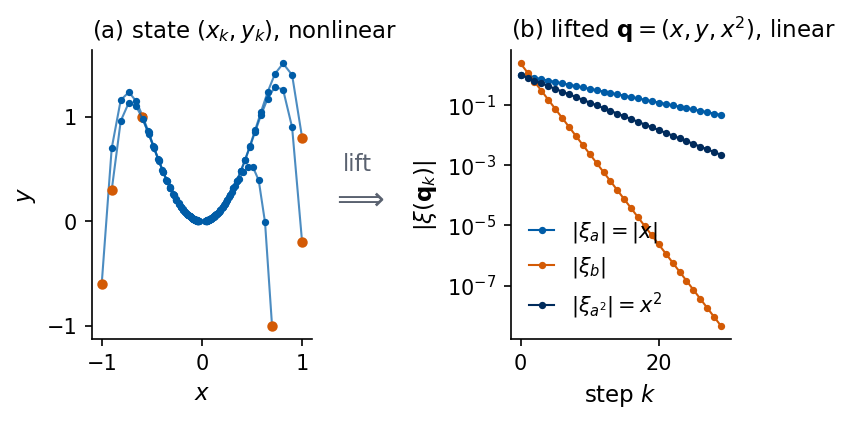

In [6]:
def lifting_figure():
    """(a) curved trajectories of the nonlinear map in the (x, y) plane; (b) the three Koopman
    eigenfunctions along one trajectory, straight lines on a log axis."""
    starts = jnp.array([[1.0, 0.8], [-1.0, -0.6], [0.7, -1.0], [-0.6, 1.0], [1.0, -0.2], [-0.9, 0.3]])
    _, tr = jax.lax.scan(lambda s, _: (lift_map(s), s), starts, None, length=30)          # (30, 6, 2)
    tr = np.asarray(tr)
    with mpl.rc_context(SLIDE_RC):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(5.5, 2.5), gridspec_kw={"wspace": 0.9})
        for j in range(tr.shape[1]):
            ax1.plot(tr[:, j, 0], tr[:, j, 1], "-", color=UJBlue, lw=1.0, alpha=0.7)
            ax1.plot(tr[:, j, 0], tr[:, j, 1], "o", color=UJBlue, ms=2.5)
            ax1.plot(tr[0, j, 0], tr[0, j, 1], "o", color=DSOrange, ms=4)
        ax1.set_xlabel(r"$x$"); ax1.set_ylabel(r"$y$")
        ax1.set_title(r"(a) state $(x_k,y_k)$, nonlinear", loc="left")
        k = np.arange(tr.shape[0]); s = tr[:, 0]                        # trajectory from (1, 0.8)
        for vals, lab, col in [(np.abs(s[:, 0]), r"$|\xi_a|=|x|$", UJBlue),
                               (np.abs(np.asarray(xi_b(jnp.asarray(s)))), r"$|\xi_b|$", DSOrange),
                               (s[:, 0]**2, r"$|\xi_{a^2}|=x^2$", UJNavy)]:
            ax2.semilogy(k, vals, "o-", ms=2.5, lw=1.0, color=col, label=lab)
        ax2.set_xlabel(r"step $k$"); ax2.set_ylabel(r"$|\xi(\mathbf{q}_k)|$")
        ax2.set_title(r"(b) lifted $\mathbf{q}=(x,y,x^2)$, linear", loc="left")
        ax2.legend(loc="lower left", handlelength=1.2)
        # arrow between the panels, placed in figure coordinates halfway between the two axes boxes
        x_mid = 0.5 * (ax1.get_position().x1 + ax2.get_position().x0) - 0.065
        fig.text(x_mid, 0.56, "lift", ha="center", fontsize=11, color=UJGray)
        fig.text(x_mid, 0.46, r"$\Longrightarrow$", ha="center", fontsize=16, color=UJGray)
    return fig

fig = lifting_figure(); save(fig, "fig_lifting"); plt.show()

The lifting is exact because the span of $(x,y,x^2)$ is invariant, mapped into itself by one step. A dictionary that contains $y^2$ is closed only if it also contains what $y^2$ turns into. One step maps $y^2$ to $(b\,y+c\,x^2)^2=b^2y^2+2bc\,x^2y+c^2x^4$, then $x^2y$ to $a^2b\,x^2y+a^2c\,x^4$ and $x^4$ to $a^4x^4$, so the six observables $(x,\,y,\,x^2,\,y^2,\,x^2y,\,x^4)$ span an invariant subspace with the matrix
$$
K_6=\begin{pmatrix}
a&0&0&0&0&0\\
0&b&c&0&0&0\\
0&0&a^2&0&0&0\\
0&0&0&b^2&2bc&c^2\\
0&0&0&0&a^2b&a^2c\\
0&0&0&0&0&a^4
\end{pmatrix}.
$$
Its eigenvalues are products of $a$ and $b$, since products of eigenfunctions are eigenfunctions. For example $\xi_b^2$ lies in the span and is multiplied by $b^2$. In contrast, for the map $x_{k+1}=a\,x_k+e\,x_k^2$ with $e\neq0$ the image of $x^n$ contains $x^{2n}$, and no finite list of powers closes.

In [7]:
g6 = sp.Matrix([x_, y_, x_**2, y_**2, x_**2 * y_, x_**4])               # the enlarged dictionary
img6 = sp.Matrix([sp.expand(gi.subs({x_: a * x_, y_: b * y_ + c * x_**2}, simultaneous=True)) for gi in g6])
for gi, ii in zip(g6, img6):
    print(f"{str(gi):6s} -> {ii}")
K6_sym = sp.Matrix([[a, 0, 0, 0, 0, 0], [0, b, c, 0, 0, 0], [0, 0, a**2, 0, 0, 0],
                    [0, 0, 0, b**2, 2*b*c, c**2], [0, 0, 0, 0, a**2*b, a**2*c], [0, 0, 0, 0, 0, a**4]])
print("g(phi(x)) - K_6 g(x) =", sp.simplify(img6 - K6_sym * g6).T)
print("eigenvalues of K_6:", list(K6_sym.eigenvals().keys()))
xi_b_sym = y_ + c / (b - a**2) * x_**2
print("xi_b^2 lies in the span and is multiplied by b^2:",
      sp.simplify(sp.expand(xi_b_sym.subs({x_: a * x_, y_: b * y_ + c * x_**2}, simultaneous=True)**2) - b**2 * xi_b_sym**2) == 0)

x      -> a*x
y      -> b*y + c*x**2
x**2   -> a**2*x**2
y**2   -> b**2*y**2 + 2*b*c*x**2*y + c**2*x**4
x**2*y -> a**2*b*x**2*y + a**2*c*x**4
x**4   -> a**4*x**4
g(phi(x)) - K_6 g(x) = Matrix([[0, 0, 0, 0, 0, 0]])
eigenvalues of K_6: [a, a**2, b, a**4, a**2*b, b**2]
xi_b^2 lies in the span and is multiplied by b^2: True


The symbolic images and the matrix confirm the closure for all parameters. The eigenvalues $a$, $b$, $a^2$, $b^2$, $a^2b$ and $a^4$ belong to the six eigenfunctions $\xi_a$, $\xi_b$, $\xi_a^2$, $\xi_b^2$, $\xi_a^2\xi_b$ and $\xi_a^4$, which span the same space as the six monomials.

<hr/>
## 3. Koopman eigenvalues of oscillating systems

The damped pendulum
$$
\dot\theta=\omega,\qquad \dot\omega=-\omega_p^2\sin\theta-\gamma\,\omega ,
$$
with the angle $\theta$, the angular velocity $\omega$, the small-amplitude frequency $\omega_p$ and the damping rate $\gamma$, has its hanging position $(0,0)$ as a stable spiral. Near this point the flow is close to its linearisation with the Jacobian $J=\begin{pmatrix}0&1\\-\omega_p^2&-\gamma\end{pmatrix}$, whose eigenvalues are
$$
\Lambda_\pm=-\frac\gamma2\pm\mathrm i\sqrt{\omega_p^2-\frac{\gamma^2}{4}} .
$$
The left eigenvector $\mathbf l=(-\omega_p^2/\Lambda,\,1)$ of $J$ gives the linear function $\xi^{\rm lin}=\mathbf l\cdot(\theta,\omega)$, for which $\mathcal A\xi^{\rm lin}-\Lambda\xi^{\rm lin}=\omega_p^2(\theta-\sin\theta)$, a defect of third order in the angle. The Koopman eigenfunctions of the pendulum with the eigenvalues $\Lambda_\pm$, the principal eigenfunctions, start as $\xi^{\rm lin}$ at the fixed point and contain higher powers of $\theta$ and $\omega$ farther away [Mauroy *et al.* 2013]. Products of the two give the eigenvalues $n_+\Lambda_++n_-\Lambda_-$ for non-negative integers $n_+$ and $n_-$, among them $\Lambda_++\Lambda_-=-\gamma$ for $|\xi|^2$, which decays at the rate of the energy of a small swing. The energy $E=\tfrac12\omega^2+\omega_p^2(1-\cos\theta)$ obeys $\mathcal AE=-\gamma\,\omega^2$. Without friction it is conserved and is an eigenfunction with $\Lambda=0$, as is every function of $E$.

A self-sustained oscillation is described by a limit cycle, a closed orbit that attracts the nearby trajectories. The Stuart–Landau oscillator, the standard model of such an oscillation, reads in polar coordinates $\dot r=r(1-r^2)$, $\dot\theta=\omega+\beta_{\mathrm{SL}}(1-r^2)$, with the limit cycle $r=1$ of angular frequency $\omega$ and the parameter $\beta_{\rm SL}$ that couples the amplitude to the frequency. Its phase eigenfunction is $\xi(r,\theta)=e^{\mathrm i(\theta-\beta_{\mathrm{SL}}\ln r)}$ with $\Lambda=\mathrm i\omega$, and its powers $\xi^n$ give the eigenvalues $\mathrm in\omega$ at all multiples of the frequency. A periodic motion is thus described by eigenvalues on the imaginary axis. The level sets of $\xi$ spiral when $\beta_{\mathrm{SL}}\neq0$, so the nonlinearity of the flow sits in the shape of the eigenfunction. We check these statements with the generator, for $\omega_p=1$ and $\gamma=0.2$ in the numbers.

In [8]:
th, om = sp.symbols("theta omega", real=True)
wp, gam = sp.symbols("omega_p gamma", positive=True)
F_pend = sp.Matrix([om, -wp**2 * sp.sin(th) - gam * om])
gen_p = lambda g: sp.expand(F_pend[0] * sp.diff(g, th) + F_pend[1] * sp.diff(g, om))

Jac = F_pend.jacobian([th, om]).subs({th: 0, om: 0})
print("Jacobian at (0, 0):", Jac.tolist(), "| eigenvalues:", [sp.simplify(l) for l in Jac.eigenvals()])
# linear eigenfunction l . (theta, omega) with the left eigenvector l = (-omega_p^2/Lambda, 1)
Lam_s = sp.Symbol("Lambda")
xi_lin = -wp**2 / Lam_s * th + om
defect = sp.simplify((gen_p(xi_lin) - Lam_s * xi_lin).subs(gam, -(Lam_s**2 + wp**2) / Lam_s))
print("A xi_lin - Lambda xi_lin =", sp.simplify(sp.expand(defect)))
E_p = om**2 / 2 + wp**2 * (1 - sp.cos(th))
print("energy: A E =", sp.simplify(gen_p(E_p)), "| without friction:", sp.simplify(gen_p(E_p).subs(gam, 0)))

WP, GAM = 1.0, 0.2
LAM_P = complex(-GAM / 2, np.sqrt(WP**2 - GAM**2 / 4))
nums["pend_Lambda"] = [LAM_P.real, LAM_P.imag]
print(f"omega_p = {WP}, gamma = {GAM}: Lambda_+- = {LAM_P.real:.4f} +- {LAM_P.imag:.5f} i")

# Stuart-Landau oscillator in polar coordinates: F = (r (1 - r^2), w + beta_SL (1 - r^2))
F_sl = sp.Matrix([r * (1 - r**2), w + bSL * (1 - r**2)])
xi_sl = sp.exp(sp.I * (th - bSL * sp.log(r)))
print("Stuart-Landau  A xi / xi =", sp.simplify(gen(F_sl, xi_sl, (r, th)) / xi_sl))

Jacobian at (0, 0): [[0, 1], [-omega_p**2, -gamma]] | eigenvalues: [-gamma/2 - sqrt(gamma**2 - 4*omega_p**2)/2, -gamma/2 + sqrt(gamma**2 - 4*omega_p**2)/2]


A xi_lin - Lambda xi_lin = omega_p**2*(theta - sin(theta))
energy: A E = -gamma*omega**2 | without friction: 0
omega_p = 1.0, gamma = 0.2: Lambda_+- = -0.1000 +- 0.99499 i
Stuart-Landau  A xi / xi = I*omega


For $\omega_p=1$ and $\gamma=0.2$ the principal eigenvalues are $\Lambda_\pm=-0.1\pm0.99499\,\mathrm i$. The generator confirms the defect $\omega_p^2(\theta-\sin\theta)$ of the linear eigenfunction, $\mathcal AE=-\gamma\omega^2$ for the energy, and $\Lambda=\mathrm i\omega$ for the Stuart–Landau phase eigenfunction.

A chaotic flow is different. Its correlation functions decay, a property called mixing, in which any small set of initial states spreads over the whole attractor. The Koopman operator of a mixing flow has a continuous spectrum, a continuum of values $\Lambda$ without eigenfunctions in the ordinary sense [Mezić 2005, Brunton *et al.* 2022]. No finite set of observables that contains the measured coordinate is then mapped into its own span, and every finite linear model is an approximation whose error accumulates under iteration. Section 5 shows this for the Lorenz signal.

<hr/>
## 4. Dynamic mode decomposition and its extension

Dynamic mode decomposition (DMD) fits a linear map to snapshot pairs [Schmid 2010]. Given $n_p$ pairs $(\mathbf x_i,\mathbf x_i')$ with $\mathbf x_i'=\varphi(\mathbf x_i)$, arranged as columns of $X,Y\in\mathbb R^{d\times n_p}$, DMD seeks the matrix $K$ that minimises the Frobenius norm $\|Y-KX\|_F$. The minimiser is
$$
K_{\mathrm{DMD}}=YX^+ ,
$$
with $X^+$ the Moore–Penrose pseudoinverse. Through the singular value decomposition $X=U\Sigma V^\top$ the pseudoinverse is $X^+=V\Sigma^{-1}U^\top$, where singular values below a relative tolerance $\epsilon_{\mathrm{rel}}\,\sigma_{\max}$ are dropped. DMD is the Koopman approximation whose dictionary consists of the state coordinates themselves. It is exact for linear dynamics.

The DMD implementation in JAX below takes $X$ and $Y$ of shape $(d,n_p)$ and is compared with `numpy.linalg.lstsq`, which solves the transposed problem $X^\top K^\top\approx Y^\top$. The data are 500 snapshot pairs of the map of Section 2 with $(x,y)$ uniform in $[-1,1]^2$.

In [9]:
def pinv_svd(X, rtol=1e-12):
    """Moore-Penrose pseudoinverse of X (n, N) via the SVD; singular values below rtol * s_max are dropped."""
    U, s, Vt = jnp.linalg.svd(X, full_matrices=False)
    s_inv = jnp.where(s > rtol * s[0], 1.0 / s, 0.0)
    return (Vt.T * s_inv) @ U.T                                   # (N, n)

@jax.jit
def dmd(X, Y):
    """DMD matrix K = Y X^+ for snapshot matrices X, Y of shape (n, N)."""
    return Y @ pinv_svd(X)

# snapshot pairs of the nonlinear map, states as columns
s_tr = jax.random.uniform(jax.random.key(2), (500, 2), minval=-1.0, maxval=1.0)
X_xy, Y_xy = s_tr.T, lift_map(s_tr).T                              # (2, 500) each
K_dmd = dmd(X_xy, Y_xy)
K_np = np.linalg.lstsq(np.asarray(X_xy).T, np.asarray(Y_xy).T, rcond=None)[0].T
nums["dmd_vs_lstsq_lifting"] = float(np.abs(np.asarray(K_dmd) - K_np).max())
nums["dmd_xy_eigs"] = sorted(np.linalg.eigvals(np.asarray(K_dmd)).real.tolist())
print("K_DMD on (x, y) =\n", np.round(np.asarray(K_dmd), 4))
print(f"max |K_JAX - K_numpy| = {nums['dmd_vs_lstsq_lifting']:.1e}")

K_DMD on (x, y) =
 [[ 0.9    -0.    ]
 [ 0.0246  0.4708]]
max |K_JAX - K_numpy| = 1.0e-16


The JAX and `numpy` matrices agree to $1\times10^{-16}$. The DMD matrix on $(x,y)$ has the eigenvalues 0.471 and 0.900. The value $0.9=a$ is recovered, because $x$ alone is closed under the map. The second eigenvalue differs from $b=0.5$. For infinitely many states uniform on the square the term $c\,x^2$ is uncorrelated with $x$ and $y$ and the fit would return $b$, so the deviation comes from the correlation of $x^2$ with $y$ on the 500 sampled states. A fit on a dictionary that does not close depends on where the data lie.

Extended DMD (EDMD) replaces the state by a dictionary of $M$ observables $\mathbf g(\mathbf x)=(g_1(\mathbf x),\dots,g_M(\mathbf x))^\top$ [Williams *et al.* 2015] and minimises the mean squared mismatch with a ridge penalty $\beta\ge0$,
$$
\frac1{n_p}\sum_{i=1}^{n_p}\bigl\|\mathbf g(\mathbf x_i')-K\mathbf g(\mathbf x_i)\bigr\|^2+\beta\,\|K\|_F^2 .
$$
Setting the derivative with respect to $K$ to zero gives
$$
K=\Sigma_1(\Sigma_0+\beta I)^{-1},\qquad
\Sigma_0=\frac1{n_p}\sum_{i}\mathbf g(\mathbf x_i)\mathbf g(\mathbf x_i)^\top,\qquad
\Sigma_1=\frac1{n_p}\sum_{i}\mathbf g(\mathbf x_i')\mathbf g(\mathbf x_i)^\top ,
$$
where $\Sigma_0$ is the uncentred covariance of the dictionary and $\Sigma_1$ its covariance with the dictionary one step later. For $\beta=0$ this is DMD applied to the lifted snapshots $\mathbf g(\mathbf x_i)$. The part of $\mathcal K\mathbf g$ that $K\mathbf g$ misses is the closure error
$$
\mathbf r(\mathbf x)=\mathbf g\bigl(\varphi(\mathbf x)\bigr)-K\mathbf g(\mathbf x),
$$
which vanishes for all $\mathbf x$ if and only if the span of the dictionary is invariant. We fit EDMD with three dictionaries and evaluate the root-mean-square (RMS) of each component of $\mathbf r$ on 2000 fresh states. The dictionary $(x,y)$ is DMD, $(x,y,x^2)$ is the invariant set of Section 2, and $(x,y,x^2,y^2)$ adds $y^2$, whose image contains $x^2y$ and $x^4$ outside the span.

In [10]:
@partial(jax.jit, static_argnums=0)
def edmd(dictionary, Xs, Ys, beta=0.0):
    """EDMD matrix K = Sigma_1 (Sigma_0 + beta I)^{-1}.  Xs, Ys: states (N, n); dictionary: (N, n) -> (N, M)."""
    PX, PY = dictionary(Xs), dictionary(Ys)                       # (N, M)
    N = PX.shape[0]
    S0 = PX.T @ PX / N                                             # Sigma_0, (M, M) uncentred covariance
    S1 = PY.T @ PX / N                                             # Sigma_1, (M, M) covariance one step later
    return jnp.linalg.solve((S0 + beta * jnp.eye(S0.shape[0])).T, S1.T).T   # Sigma_1 (Sigma_0 + beta I)^{-1}

dictionaries = {
    "xy":     lambda s: s,
    "xyx2":   lift_obs,
    "xyx2y2": lambda s: jnp.concatenate([lift_obs(s), s[:, 1:2]**2], axis=1),
}
s_te = jax.random.uniform(jax.random.key(3), (2000, 2), minval=-1.0, maxval=1.0)   # fresh test states
K_edmd, closure = {}, {}
for name, dic in dictionaries.items():
    K = edmd(dic, s_tr, lift_map(s_tr))
    r_test = dic(lift_map(s_te)) - dic(s_te) @ K.T               # closure error r(x) on test states, (2000, M)
    K_edmd[name] = K
    closure[name] = np.sqrt(np.mean(np.asarray(r_test)**2, axis=0)).tolist()
    print(f"dictionary {name:7s}: RMS closure error per component", np.array2string(np.array(closure[name]), precision=3))
nums["closure_rms"] = closure
nums["edmd_K_maxdiff_exact"] = float(jnp.abs(K_edmd["xyx2"] - K_lift).max())
print(f"max |K_EDMD - K| for the dictionary (x, y, x^2): {nums['edmd_K_maxdiff_exact']:.1e}")
# EDMD with beta = 0 is DMD on the lifted snapshots
print("EDMD(beta=0) equals DMD on lifted snapshots:",
      bool(jnp.allclose(K_edmd["xyx2"], dmd(lift_obs(s_tr).T, lift_obs(lift_map(s_tr)).T), atol=1e-10)))

dictionary xy     : RMS closure error per component [1.317e-16 4.450e-01]


dictionary xyx2   : RMS closure error per component [1.316e-16 5.809e-16 1.530e-16]


dictionary xyx2y2 : RMS closure error per component [2.629e-16 2.527e-16 2.573e-16 1.927e-01]
max |K_EDMD - K| for the dictionary (x, y, x^2): 8.9e-16


EDMD(beta=0) equals DMD on lifted snapshots: True


The dictionary $(x,y,x^2)$ recovers the matrix $K$ of Section 2 to $9\times10^{-16}$, and its closure error is at round-off level, at most $6\times10^{-16}$. The dictionary $(x,y)$ leaves an RMS error of 0.445 in the $y$ component, which is the term $c\,x^2$ projected out of the span. Adding $y^2$ keeps the first three components closed and introduces an error of 0.193 in the new component. The six-function dictionary of Section 2 closes again.

In [11]:
dic6 = lambda s: jnp.stack([s[:, 0], s[:, 1], s[:, 0]**2, s[:, 1]**2, s[:, 0]**2 * s[:, 1], s[:, 0]**4], axis=1)
K6 = edmd(dic6, s_tr, lift_map(s_tr))
r6 = np.sqrt(np.mean(np.asarray(dic6(lift_map(s_te)) - dic6(s_te) @ K6.T)**2, axis=0))
K6_num = np.array(K6_sym.subs({a: A_PAR, b: B_PAR, c: C_PAR}), float)
nums["closure_six"] = r6.tolist()
nums["edmd_K6_maxdiff"] = float(np.abs(np.asarray(K6) - K6_num).max())
print("dictionary (x, y, x^2, y^2, x^2 y, x^4): RMS closure error per component", np.array2string(r6, precision=3))
print(f"max |K_EDMD - K_6| = {nums['edmd_K6_maxdiff']:.1e}")

dictionary (x, y, x^2, y^2, x^2 y, x^4): RMS closure error per component [3.154e-16 3.855e-16 3.734e-16 1.130e-15 2.034e-16 1.285e-15]
max |K_EDMD - K_6| = 1.4e-14


With $(x,y,x^2,y^2,x^2y,x^4)$ every component has a closure error of at most $1\times10^{-15}$, and the fitted matrix agrees with $K_6$ to $1\times10^{-14}$. Closure is a property of the subspace that the dictionary spans, and a larger dictionary can close worse or better than a smaller one.

Iterating the fitted matrices from one initial state shows how the closure error accumulates in a forecast. The plotted quantity is $y_k$ for the true map and the readout $\mathbf e_2^\top K^k\mathbf g(\mathbf x_0)$ for the two fitted matrices.

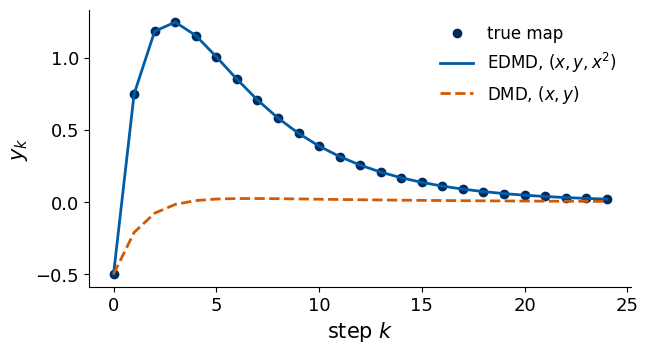

max |y_k - EDMD forecast| = 2.9e-15,  max |y_k - DMD forecast| = 1.265


In [12]:
s_init = jnp.array([[1.0, -0.5]])
_, tr_true = jax.lax.scan(lambda s, _: (lift_map(s), s), s_init, None, length=25)
y_true = np.asarray(tr_true[:, 0, 1])
roll = lambda K, z0: np.array([(jnp.linalg.matrix_power(K, m) @ z0)[1] for m in range(25)])
y_xy = roll(K_edmd["xy"], s_init[0])
y_xyx2 = roll(K_edmd["xyx2"], lift_obs(s_init)[0])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(y_true, "o", color=UJNavy, label="true map")
ax.plot(y_xyx2, "-", color=UJBlue, label=r"EDMD, $(x,y,x^2)$")
ax.plot(y_xy, "--", color=DSOrange, label=r"DMD, $(x,y)$")
ax.set_xlabel(r"step $k$"); ax.set_ylabel(r"$y_k$"); ax.legend(); plt.show()
print(f"max |y_k - EDMD forecast| = {np.abs(y_true - y_xyx2).max():.1e},  max |y_k - DMD forecast| = {np.abs(y_true - y_xy).max():.3f}")

For the pendulum the Koopman eigenfunctions are not polynomials, and EDMD with a polynomial dictionary can only approximate them. We fit EDMD with all 36 monomials $1,\theta,\omega,\theta^2,\theta\omega,\dots,\omega^7$ of total degree up to 7 on 4000 pairs of states one step $\Delta t=0.1$ apart, the first state of each pair uniform in $[-1,1]^2$, with $\beta=10^{-8}$, and convert the eigenvalues $\nu$ to $\Lambda=\ln\nu/\Delta t$. The flow is integrated with RK4 steps of 0.01. For the frictionless pendulum we compare with the energy and with the frequency $\Omega(E)=\pi\omega_p/(2\mathsf K(k))$ of a swing of energy $E$, where $k=\sin(\theta_{\max}/2)$, $E=\omega_p^2(1-\cos\theta_{\max})$ and $\mathsf K$ is the complete elliptic integral of the first kind. The formula follows from energy conservation, which gives the period as four times $\int_0^{\theta_{\max}}d\theta/\omega(\theta)$ with $\omega(\theta)=\sqrt{2(E-\omega_p^2(1-\cos\theta))}$.

gamma = 0.2: Lambda   exact -0.1000+0.9950j, EDMD -0.1001+0.9942j
gamma = 0.2: 2Lambda  exact -0.2000+1.9900j, EDMD -0.1749+2.0063j
gamma = 0.2: sum      exact -0.2000, EDMD -0.1991+0.0000j


gamma = 0: eigenvalue -1.7e-07, energy reproduced to 4.7e-04; band Omega(E) from 0.8549 to 1; EDMD frequencies [0.7464, 0.9311, 0.9555, 0.984]; largest Re Lambda 0.042


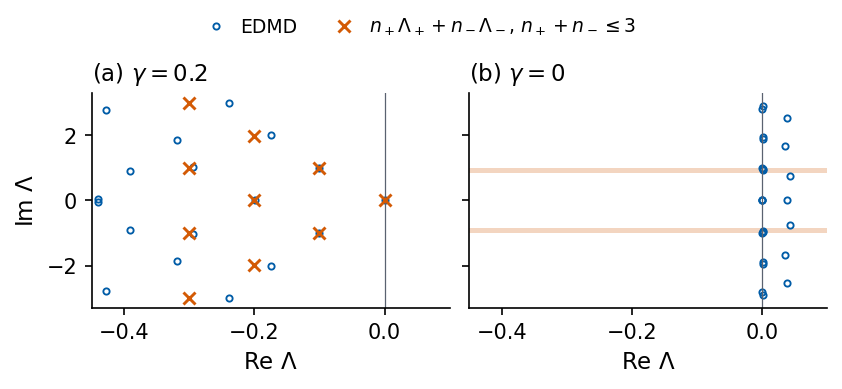

In [13]:
from scipy.special import ellipk

def pend_rhs(g):
    return lambda u: jnp.stack([u[..., 1], -WP**2 * jnp.sin(u[..., 0]) - g * u[..., 1]], -1)

@partial(jax.jit, static_argnums=(1, 2))
def pend_flow(u, n_steps, g):
    """n_steps RK4 steps of length 0.01 for a batch of pendulum states u (..., 2)."""
    f = pend_rhs(g)
    return jax.lax.fori_loop(0, n_steps, lambda i, q: rk4_step(f, q, 0.01), u)

D_P, DT_P = 7, 0.1
def monomials(s):
    """All monomials theta^i omega^j of total degree i + j <= 7, 36 functions."""
    return jnp.stack([s[:, 0]**i * s[:, 1]**j for i in range(D_P + 1) for j in range(D_P + 1 - i)], axis=1)

Xp = jax.random.uniform(jax.random.key(7), (4000, 2), minval=-1.0, maxval=1.0)
Xt = jax.random.uniform(jax.random.key(8), (500, 2), minval=-1.0, maxval=1.0)
energy_p = lambda s: 0.5 * s[:, 1]**2 + WP**2 * (1 - jnp.cos(s[:, 0]))
pend_res = {}
for g in (GAM, 0.0):
    Kp = np.asarray(edmd(monomials, Xp, pend_flow(Xp, int(round(DT_P / 0.01)), g), 1e-8))
    nu_p, Cp = np.linalg.eig(Kp.T)                      # columns of Cp: eigenfunction coefficients c, xi = c . g
    pend_res[g] = (np.log(nu_p.astype(complex)) / DT_P, Cp)

Lp, _ = pend_res[GAM]
for name, target in (("Lambda", LAM_P), ("2Lambda", 2 * LAM_P), ("sum", 2 * LAM_P.real)):
    j = np.argmin(np.abs(Lp - target))
    nums[f"pend_edmd_{name}"] = [Lp[j].real, abs(Lp[j].imag)]
    print(f"gamma = {GAM}: {name:8s} exact {target:.4f}, EDMD {Lp[j]:.4f}")

L0, C0 = pend_res[0.0]
Et = np.asarray(energy_p(Xt)); P0 = np.asarray(monomials(Xt))
best = None
for j in np.where(np.abs(L0) < 0.01)[0]:
    val = (P0 @ C0[:, j]).real
    A_ = np.stack([val, np.ones_like(val)], 1)
    err = np.linalg.norm(A_ @ np.linalg.lstsq(A_, Et, rcond=None)[0] - Et) / np.linalg.norm(Et - Et.mean())
    if best is None or err < best[1]:
        best = (L0[j].real, err)
nums["pend_energy_fit"] = [best[0], best[1]]
E_corner = float(energy_p(jnp.array([[1.0, 1.0]]))[0])
Om_min = float(np.pi * WP / (2 * ellipk(np.sin(np.arccos(1 - E_corner / WP**2) / 2)**2)))
osc0 = L0[(np.abs(L0.imag) > 0.5) & (np.abs(L0.imag) < 1.5)]
nums["pend_frictionless"] = dict(E_corner=E_corner, Omega_min=Om_min, freqs=sorted(set(np.abs(osc0.imag).round(4).tolist())),
                                 max_growth=float(L0.real.max()))
print(f"gamma = 0: eigenvalue {best[0]:.1e}, energy reproduced to {best[1]:.1e}; band Omega(E) from {Om_min:.4f} to 1;"
      f" EDMD frequencies {nums['pend_frictionless']['freqs']}; largest Re Lambda {L0.real.max():.3f}")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.5), sharey=True, layout="constrained")
    for ax, g, title in ((axs[0], GAM, rf"(a) $\gamma={GAM}$"), (axs[1], 0.0, r"(b) $\gamma=0$")):
        Lg = pend_res[g][0]
        ax.plot(Lg.real, Lg.imag, "o", ms=3.0, mfc="none", mew=0.9, color=UJBlue, label="EDMD")
        ax.set_title(title, loc="left"); ax.set_xlabel(r"Re $\Lambda$")
        ax.set_xlim(-0.45, 0.1); ax.set_ylim(-3.3, 3.3); ax.axvline(0, color=UJGray, lw=0.6)
    exact = np.array([m_ * LAM_P + n_ * LAM_P.conjugate() for m_ in range(4) for n_ in range(4) if m_ + n_ <= 3])
    axs[0].plot(exact.real, exact.imag, "x", color=DSOrange, ms=6, mew=1.4, label=r"$n_+\Lambda_++n_-\Lambda_-$, $n_++n_-\leq3$")
    for sgn in (1, -1):
        axs[1].axhspan(sgn * Om_min, sgn * WP, color=DSOrange, alpha=0.25, lw=0)
    axs[0].set_ylabel(r"Im $\Lambda$")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=2, fontsize=9, handlelength=1.0)
    save(fig, "fig_lab035_pendulum_edmd"); plt.show()

With friction, panel (a), EDMD returns $\Lambda=-0.1001\pm0.9942\,\mathrm i$ against $\Lambda_\pm=-0.1\pm0.99499\,\mathrm i$, the real value $-0.1991$ against $\Lambda_++\Lambda_-=-0.2$, and $-0.1749\pm2.0063\,\mathrm i$ against $2\Lambda_\pm=-0.2\pm1.990\,\mathrm i$. The fitted values lie close to the lattice $n_+\Lambda_++n_-\Lambda_-$ (crosses), the lower ones closest. The eigenvalue $\Lambda=0$ belongs to the constant function, which every flow leaves unchanged.

Without friction, panel (b), one eigenvalue $\Lambda=-1.7e-07$ has an eigenfunction that reproduces the energy, up to a constant and a factor, with a relative error of $5\times10^{-4}$ on 500 test states. The energies of the sampled square reach $0.960$, so the swings have frequencies between $\Omega=0.8549$ and 1 (shaded band). The oscillating eigenvalues do not settle on one frequency. They are scattered over the band and beyond it, and they have positive real parts up to $0.042$, a spurious growth. The phase of a frictionless swing advances at a rate that depends on its energy, so the oscillating part of the spectrum on this region is a continuous band that no finite dictionary represents. Friction removes the band, since every swing decays to the same fixed point, whose linearisation sets one pair $\Lambda_\pm$ for the whole basin.

<hr/>
## 5. Delay dynamic mode decomposition

A measured signal $s_k=h(\mathbf x_k)$ is one observable of an unknown state, so neither DMD on the state nor a dictionary of chosen functions of the state can be applied directly. The delay vector of window length $L$, built from consecutive samples (delay $\kappa=1$) with the newest sample first,
$$
\mathbf u_k=(s_k,s_{k-1},\dots,s_{k-L+1})^\top\in\mathbb R^L ,
$$
contains the same observable evaluated at time-lagged states, $s_{k-j}=h(\mathbf x_{k-j})$. For an invertible map this is $(\mathcal K^{-j}h)(\mathbf x_k)$, so the delay vector is a dictionary generated by the Koopman operator from the single measurement $h$. Takens' theorem guarantees that for $L$ large enough this vector embeds the attractor [Takens 1981], and the Koopman reading adds that a linear map on $\mathbf u_k$ is a finite Koopman approximation. Stacking the delay vectors as columns gives a Hankel matrix, constant along its antidiagonals, which is why the method is also called Hankel DMD. The fitted matrix is $K=YX^+$ with $X=[\mathbf u_{L-1},\dots,\mathbf u_{N-2}]$ and $Y=[\mathbf u_L,\dots,\mathbf u_{N-1}]$, and a forecast iterates $\mathbf u\mapsto K\mathbf u$ and reads the first component, the newest sample. In the code the window is stored in the reverse order, oldest sample first, so the newest sample is the last entry of each array and the arrays hold $K$ with the order of its rows and columns reversed. The eigenvalues do not depend on this ordering.

We apply the method to three signals of $N=4000$ samples each, rescaled to $[0,1]$ with the minimum and maximum of the fitting part of the training block (the first 2500 samples) and centred with its mean. The two-harmonic signal $s(t)=\sin t+\tfrac12\sin2t$ sampled with $\Delta t=0.05$ spans four Fourier modes and is the simplest periodic case. The Mackey–Glass signal with delay $\tau_{\mathrm{MG}}=15$ is a limit cycle with many harmonics, and the Lorenz $x$ signal with $\Delta t=0.02$ is chaotic. The window length must cover the slowest structure of the signal. We use $L=20$ for the two-harmonic and Lorenz signals and $L=100$ for Mackey–Glass, longer than its period, which we measure from the gaps between successive maxima.

In [14]:
N_TWO_DT, N_LOR_DT = 0.05, 0.02
t_two = np.arange(N_SAMPLES) * N_TWO_DT
raw = {"two": np.sin(t_two) + 0.5 * np.sin(2 * t_two),
       "mg15": mackey_glass(15, N_SAMPLES),
       "lorenz": np.asarray(lorenz_trajectory(N_SAMPLES))[:, 0]}
DT = {"two": N_TWO_DT, "mg15": 1.0, "lorenz": N_LOR_DT}
L_WIN = {"two": 20, "mg15": 100, "lorenz": 20}
LABEL = {"two": "two harmonics", "mg15": r"Mackey–Glass $\tau_{\rm MG}=15$", "lorenz": r"Lorenz $x$"}

sig = {}
for k, s in raw.items():
    s01 = rescale01(s)
    sig[k] = s01 - s01[:N_TRAIN].mean()                 # centred with the training mean

# period of the Mackey-Glass limit cycle from the gaps between local maxima
s = raw["mg15"]
peaks = np.where((s[1:-1] > s[:-2]) & (s[1:-1] > s[2:]))[0] + 1
gaps = np.diff(peaks)
print("gaps between successive maxima (samples), first 9:", gaps[:9], "| last 9:", gaps[-9:])
nums["mg15_peak_gaps"] = gaps[:3].tolist()
three = gaps[:-2] + gaps[1:-1] + gaps[2:]                       # length of three consecutive gaps = one period
print("values of three consecutive gaps:", np.unique(three))
m = (len(peaks) - 1) // 3                                       # whole periods between the first and a later maximum
nums["mg15_period_samples"] = float((peaks[3 * m] - peaks[0]) / m)
print(f"Mackey-Glass period: {nums['mg15_period_samples']:.3f} samples (average over {m} periods)")

def hankel(s, L):
    """Delay vectors as columns, stored oldest sample first, (s_{k-L+1}, ..., s_k); shape (L, len(s) - L + 1)."""
    n = len(s) - L + 1
    return jnp.stack([jnp.asarray(s[j:j + n]) for j in range(L)])

gaps between successive maxima (samples), first 9: [11 46 33 11 46 33 11 46 33] | last 9: [46 33 11 46 33 11 46 33 11]
values of three consecutive gaps: [89 90]
Mackey-Glass period: 89.864 samples (average over 44 periods)


The maxima of the Mackey–Glass signal repeat with gaps 11, 46, 33 samples, so the limit cycle has period 89.86 samples and three maxima per period. We fit the delay DMD on the training block of each signal. For each eigenvalue $\nu_j$ of $K$ the continuous-time value is $\Lambda_j=\ln\nu_j/\Delta t$, whose real part is a growth rate and imaginary part an angular frequency. For the Lorenz signal we also compare the JAX matrix with `numpy.linalg.lstsq`.

In [15]:
K_hank, eigs = {}, {}
for k in sig:
    U = hankel(sig[k][:N_TRAIN], L_WIN[k])                   # (L, n) delay vectors of the training block
    K_hank[k] = dmd(U[:, :-1], U[:, 1:])
    eigs[k] = np.linalg.eigvals(np.asarray(K_hank[k]))
    print(f"{k:7s} L = {L_WIN[k]:3d}   max |nu| = {np.abs(eigs[k]).max():.5f}")

U = hankel(sig["lorenz"][:N_TRAIN], 20)
K_np = np.linalg.lstsq(np.asarray(U[:, :-1]).T, np.asarray(U[:, 1:]).T, rcond=None)[0].T
nums["dmd_vs_lstsq_lorenz"] = float(np.abs(np.asarray(K_hank["lorenz"]) - K_np).max())
sv = np.linalg.svd(np.asarray(U[:, :-1]), compute_uv=False)
nums["lorenz_hankel_sv_ratio"] = float(sv[-1] / sv[0])
print(f"Lorenz: max |K_JAX - K_numpy| = {nums['dmd_vs_lstsq_lorenz']:.1e}; "
      f"smallest / largest singular value of X = {nums['lorenz_hankel_sv_ratio']:.1e}")

# two harmonics: eigenvalues with |nu| > 0.5 sit on the unit circle at frequencies 0, +-1, +-2
ev = eigs["two"][np.abs(eigs["two"]) > 0.5]
mu = np.log(ev.astype(complex)) / DT["two"]
nums["two_imag_mu"] = sorted(np.round(mu.imag, 6).tolist())
nums["two_lam_mod_max_dev"] = float(np.abs(np.abs(ev) - 1).max())
print("two harmonics: Im Lambda of the unit-circle eigenvalues:", nums["two_imag_mu"],
      f"| max ||nu| - 1| = {nums['two_lam_mod_max_dev']:.1e}",
      f"| other eigenvalues: max |nu| = {np.abs(eigs['two'][np.abs(eigs['two']) <= 0.5]).max():.1e}")

# Mackey-Glass: the slowest oscillating pair against the fundamental frequency 2 pi / period
ev = eigs["mg15"]; mu = np.log(ev.astype(complex))
pair = ev[np.argsort(-np.abs(ev))]
pair = pair[np.abs(pair.imag) > 1e-8]
order = np.argsort(np.abs(np.angle(pair[np.abs(pair) > 0.999])))
fund = pair[np.abs(pair) > 0.999][order][0]
nums["mg15_imag_mu_fund"] = float(abs(np.angle(fund)))
nums["mg15_omega_from_period"] = float(2 * np.pi / nums["mg15_period_samples"])
nums["mg15_lam_max"] = float(np.abs(eigs["mg15"]).max())
print(f"Mackey-Glass: smallest |Im Lambda| among |nu| > 0.999: {nums['mg15_imag_mu_fund']:.5f}",
      f"| 2 pi / period = {nums['mg15_omega_from_period']:.5f}",
      f"| eigenvalues with |nu| > 0.999: {(np.abs(ev) > 0.999).sum()} of {len(ev)}")
nums["mg15_n_unit"] = int((np.abs(ev) > 0.999).sum())
nums["lor_lam_max"] = float(np.abs(eigs["lorenz"]).max())
nums["lor_lam_max_mu_re"] = float(np.log(nums["lor_lam_max"]) / DT["lorenz"])
print(f"Lorenz: max |nu| = {nums['lor_lam_max']:.4f}, slowest decay rate Re mu = {nums['lor_lam_max_mu_re']:.3f} per time unit")

two     L =  20   max |nu| = 1.00000


mg15    L = 100   max |nu| = 1.00005
lorenz  L =  20   max |nu| = 0.95126


Lorenz: max |K_JAX - K_numpy| = 1.9e-07; smallest / largest singular value of X = 2.5e-09
two harmonics: Im Lambda of the unit-circle eigenvalues: [-2.0, -1.0, 0.0, 1.0, 2.0] | max ||nu| - 1| = 5.1e-10 | other eigenvalues: max |nu| = 1.1e-12
Mackey-Glass: smallest |Im Lambda| among |nu| > 0.999: 0.06992 | 2 pi / period = 0.06992 | eigenvalues with |nu| > 0.999: 88 of 100
Lorenz: max |nu| = 0.9513, slowest decay rate Re mu = -2.498 per time unit


The JAX and `numpy` fits of the Lorenz matrix agree to $2\times10^{-7}$. This is far above round-off because twenty samples spaced by $\Delta t=0.02$ are strongly correlated, and the smallest singular value of $X$ is $3\times10^{-9}$ times the largest, which amplifies round-off errors in the fit. For the two-harmonic signal five eigenvalues lie on the unit circle (deviation of $|\nu|$ from one at most $5\times10^{-10}$) with imaginary parts $\mathrm{Im}\,\Lambda$ equal to -2.000000, -1.000000, 0.000000, 1.000000, 2.000000, the frequencies $0,\pm1,\pm2$ of the signal, where the zero frequency carries the small offset left by centring with the training mean. The other fifteen eigenvalues are zero within round-off, since the delay vectors span only five dimensions and the pseudoinverse discards the rest. For Mackey–Glass the spectral radius is 1.00005, 88 of the 100 eigenvalues have $|\nu|>0.999$, and the slowest oscillating one has angle 0.06992 per sample, against $2\pi/89.86=0.06992$ from the measured period. The Lorenz eigenvalues all lie inside the circle, with spectral radius 0.951.

The figure shows the eigenvalues in the complex plane together with the unit circle $|\nu|=1$.

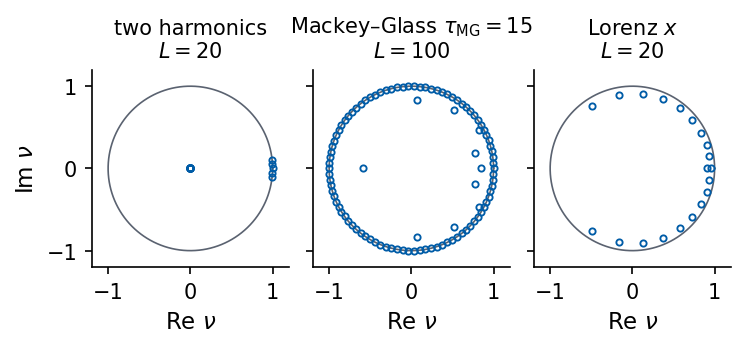

In [16]:
def eig_figure():
    with mpl.rc_context(SLIDE_RC):
        fig, axes = plt.subplots(1, 3, figsize=(5.5, 2.4), sharey=True, gridspec_kw={"wspace": 0.12})
        ph = np.linspace(0, 2 * np.pi, 400)
        for ax, k in zip(axes, ["two", "mg15", "lorenz"]):
            ax.plot(np.cos(ph), np.sin(ph), color=UJGray, lw=0.8)
            ax.plot(eigs[k].real, eigs[k].imag, "o", ms=3.0, mfc="none", mew=0.9, color=UJBlue)
            ax.set_aspect("equal"); ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2)
            ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1])
            ax.set_title(LABEL[k] + f"\n$L={L_WIN[k]}$", fontsize=10)
            ax.set_xlabel(r"Re $\nu$")
        axes[0].set_ylabel(r"Im $\nu$")
    return fig

fig = eig_figure(); save(fig, "fig_delay_dmd_eigs"); plt.show()

The decay of the Lorenz modes should be compared with the time scale on which the Lorenz flow itself loses information about its initial state, the inverse largest Lyapunov exponent $T_\lambda=1/\lambda_1$ . We estimate $\lambda_1$ with the tangent-vector method [Benettin *et al.* 1980]. A tangent vector $\boldsymbol\delta_j$ is propagated with the Jacobian of the RK4 step, obtained by `jax.jvp`, and renormalised to unit length after every step. With $n$ integration steps of length $\Delta t_{\rm RK}=0.01$,
$$
\lambda_1=\frac{1}{n\,\Delta t_{\rm RK}}\sum_{j=1}^{n}\ln\|J(\mathbf x_{j-1})\,\boldsymbol\delta_{j-1}\| ,
$$
where $J$ is the Jacobian of one RK4 step. We average over $4000$ time units and split them into four blocks of $1000$ time units to measure the spread.

In [17]:
H_LOR = 0.01
lor_step = lambda u: rk4_step(lorenz_rhs, u, H_LOR)

@partial(jax.jit, static_argnums=2)
def lyap_log_growth(u0, d0, n):
    """Propagate state u and tangent vector d with the RK4 step and its Jacobian; returns ln|d| growth per step."""
    def body(carry, _):
        u, d = carry
        u1, d1 = jax.jvp(lor_step, (u,), (d,))        # u1 = step(u), d1 = J(u) d
        nd = jnp.linalg.norm(d1)
        return (u1, d1 / nd), jnp.log(nd)
    _, logs = jax.lax.scan(body, (u0, d0), None, length=n)
    return logs

u_att = lorenz_trajectory(1)[0]                       # a point on the attractor (after the transient)
logs = np.asarray(lyap_log_growth(u_att, jnp.array([1.0, 0.0, 0.0]), 401000))[1000:]   # drop 10 time units of alignment
blocks = logs.reshape(4, -1).sum(axis=1) / (logs.size / 4 * H_LOR)
nums["lorenz_lyap1"] = float(logs.sum() / (logs.size * H_LOR))
nums["lorenz_lyap1_blocks"] = blocks.tolist()
nums["lorenz_lyap1_block_std"] = float(blocks.std(ddof=1))
nums["lorenz_lyap_time"] = 1.0 / nums["lorenz_lyap1"]
nums["lorenz_lyap_time_samples"] = nums["lorenz_lyap_time"] / N_LOR_DT
print(f"lambda_1 = {nums['lorenz_lyap1']:.4f} per time unit (4000 time units); blocks of 1000:",
      np.round(blocks, 4), f"(std {nums['lorenz_lyap1_block_std']:.4f})")
print(f"Lyapunov time T = 1/lambda_1 = {nums['lorenz_lyap_time']:.3f} time units = {nums['lorenz_lyap_time_samples']:.1f} samples")

lambda_1 = 0.9022 per time unit (4000 time units); blocks of 1000: [0.9041 0.9058 0.8912 0.9078] (std 0.0075)
Lyapunov time T = 1/lambda_1 = 1.108 time units = 55.4 samples


We obtain $\lambda_1=0.902$ per time unit, with block values 0.904, 0.906, 0.891, 0.908 (standard deviation 0.008), so $T_\lambda=1.11$ time units, or 55 samples of the Lorenz signal.

We now iterate each fitted matrix in closed loop, $\mathbf u\mapsto K\mathbf u$, from origins in the test block (the last 1000 samples), so that the forecasts use data the fit never saw. The origins are every fifth sample for which the initial window and 300 forecast steps lie inside the test block. For each lead $\tau$ we report
$$
\mathrm{NRMSE}(\tau)=\frac{\bigl\langle(\hat s_{k+\tau}-s_{k+\tau})^2\bigr\rangle^{1/2}}{\sigma_{\rm test}},\qquad
A(\tau)=\frac{\bigl\langle\hat s_{k+\tau}^{\,2}\bigr\rangle^{1/2}}{\sigma_{\rm test}},
$$
where $\langle\cdot\rangle$ averages over origins $k$, $\hat s_{k+\tau}$ is the first component of $K^\tau\mathbf u_k$, and $\sigma_{\rm test}$ is the standard deviation of the test block. The normalised root-mean-square error (NRMSE) equals about one for a forecast that returns the mean, and $A(\tau)$ measures how far the forecast still moves away from the training mean.

In [18]:
H_ROLL = 300

@partial(jax.jit, static_argnums=2)
def rollout(K, u0, n):
    """Closed-loop forecast: iterate u -> K u for n steps and return the last component, shape (n,)."""
    _, out = jax.lax.scan(lambda u, _: (K @ u, (K @ u)[-1]), u0, None, length=n)
    return out

def rollout_scores(k, K=None, L=None):
    K = K_hank[k] if K is None else K
    L = L_WIN[k] if L is None else L
    s = sig[k]
    U = hankel(s, L)                                    # column j = u_{j+L-1}
    last = np.arange(N_TRAIN + L - 1, N_SAMPLES - H_ROLL, 5)          # index of the last sample in the window
    preds = jax.vmap(lambda u: rollout(K, u, H_ROLL))(U[:, last - L + 1].T)   # (n_origins, H)
    truth = np.stack([s[i + 1:i + 1 + H_ROLL] for i in last])
    sd = s[N_TRAIN:].std()
    nrmse = np.sqrt(np.mean((np.asarray(preds) - truth)**2, axis=0)) / sd
    amp = np.sqrt(np.mean(np.asarray(preds)**2, axis=0)) / sd
    return last, np.asarray(preds), truth, nrmse, amp

scores = {k: rollout_scores(k) for k in sig}
nums["n_origins"] = int(len(scores["lorenz"][0]))
nums["two_nrmse_max"] = float(scores["two"][3].max())
nums["mg15_nrmse_max"] = float(scores["mg15"][3].max())
_, _, _, nr, amp = scores["lorenz"]
h_tl = int(round(nums["lorenz_lyap_time_samples"]))
nums["lor_first_lead_nrmse_half"] = int(np.argmax(nr > 0.5) + 1)
nums["lor_first_time_nrmse_half"] = nums["lor_first_lead_nrmse_half"] * N_LOR_DT
nums["lor_nrmse_at_tlyap"] = float(nr[h_tl - 1])
nums["lor_amp_at_tlyap"] = float(amp[h_tl - 1])
nums["lor_amp_at_2tlyap"] = float(amp[2 * h_tl - 1])
for k in sig:
    print(f"{k:7s} origins {len(scores[k][0])}, NRMSE at tau = 1, 10, 50, 300:",
          np.array2string(scores[k][3][[0, 9, 49, 299]], precision=4))
print(f"Lorenz: first lead with NRMSE > 0.5: tau = {nums['lor_first_lead_nrmse_half']} "
      f"(t = {nums['lor_first_time_nrmse_half']:.2f}); at tau = {h_tl} (one Lyapunov time): NRMSE = {nr[h_tl - 1]:.3f}, "
      f"A = {amp[h_tl - 1]:.3f}; at two Lyapunov times A = {amp[2 * h_tl - 1]:.4f}")

two     origins 137, NRMSE at tau = 1, 10, 50, 300: [4.9100e-13 8.9391e-11 2.0399e-08 8.8422e-08]
mg15    origins 121, NRMSE at tau = 1, 10, 50, 300: [1.1132e-06 1.6663e-05 1.7019e-05 6.7507e-05]
lorenz  origins 137, NRMSE at tau = 1, 10, 50, 300: [4.0961e-05 2.4002e-01 1.0036e+00 1.0146e+00]
Lorenz: first lead with NRMSE > 0.5: tau = 14 (t = 0.28); at tau = 55 (one Lyapunov time): NRMSE = 0.986, A = 0.118; at two Lyapunov times A = 0.0050


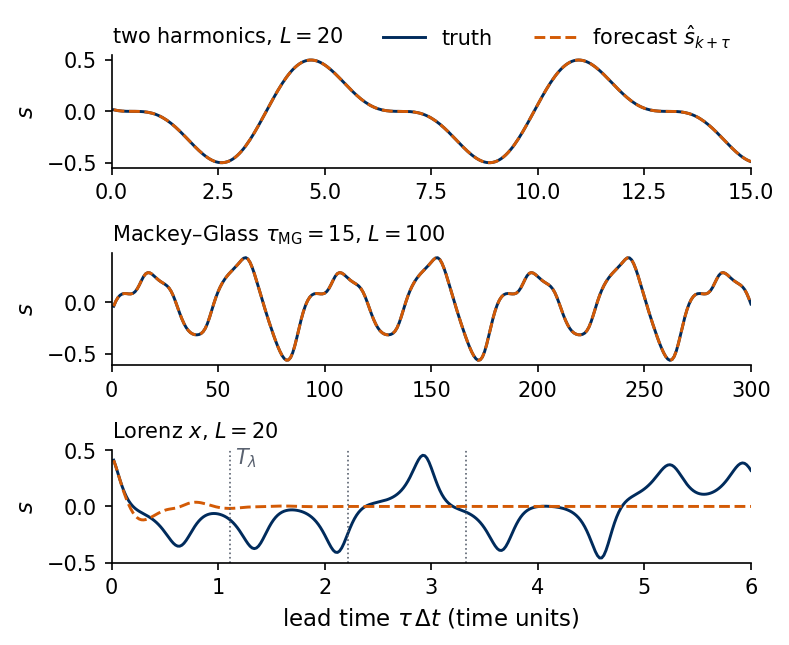

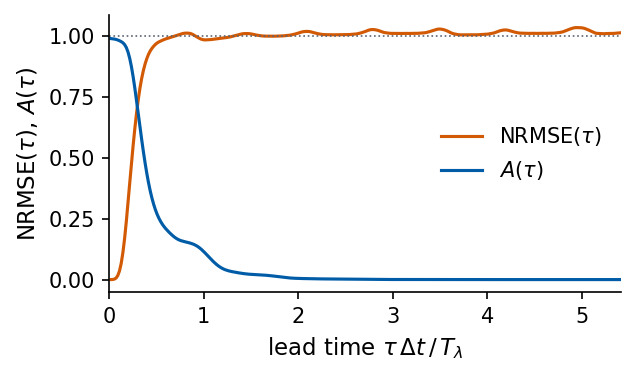

In [19]:
def rollout_figure(i_origin=10):
    with mpl.rc_context(SLIDE_RC):
        fig, axes = plt.subplots(3, 1, figsize=(5.5, 4.4), sharex=False, gridspec_kw={"hspace": 0.75})
        for ax, k in zip(axes, ["two", "mg15", "lorenz"]):
            last, preds, truth, _, _ = scores[k]
            tt = np.arange(1, H_ROLL + 1) * DT[k]
            ax.plot(tt, truth[i_origin], color=UJNavy, lw=1.4, label="truth")
            ax.plot(tt, preds[i_origin], "--", color=DSOrange, lw=1.4, label=r"forecast $\hat s_{k+\tau}$")
            ax.set_title(LABEL[k] + f", $L={L_WIN[k]}$", loc="left", fontsize=10)
            ax.set_ylabel(r"$s$")
            if k == "lorenz":
                for m in (1, 2, 3):
                    ax.axvline(m * nums["lorenz_lyap_time"], color=UJGray, lw=0.8, ls=":")
                ax.text(nums["lorenz_lyap_time"] + 0.05, ax.get_ylim()[1] * 0.75, r"$T_\lambda$", color=UJGray, fontsize=10)
            ax.set_xlim(0, tt[-1])
        axes[0].legend(loc="upper right", ncol=2, fontsize=10, bbox_to_anchor=(1.0, 1.45))
        axes[-1].set_xlabel(r"lead time $\tau\,\Delta t$ (time units)")
    return fig

fig = rollout_figure(); save(fig, "fig_delay_dmd_rollout"); plt.show()

def nrmse_figure():
    _, _, _, nr, amp = scores["lorenz"]
    tt = np.arange(1, H_ROLL + 1) * DT["lorenz"] / nums["lorenz_lyap_time"]
    with mpl.rc_context(SLIDE_RC):
        fig, ax = plt.subplots(figsize=(4.4, 2.4))
        ax.plot(tt, nr, color=DSOrange, label=r"NRMSE$(\tau)$")
        ax.plot(tt, amp, color=UJBlue, label=r"$A(\tau)$")
        ax.axhline(1.0, color=UJGray, lw=0.8, ls=":")
        ax.set_xlabel(r"lead time $\tau\,\Delta t\,/\,T_\lambda$"); ax.set_ylabel(r"NRMSE$(\tau)$, $A(\tau)$")
        ax.set_xlim(0, tt[-1]); ax.legend(loc="center right")
    return fig

fig = nrmse_figure(); save(fig, "fig_delay_dmd_nrmse"); plt.show()

The rollouts in the figure start from the eleventh origin of the test block. For the two-harmonic signal the largest NRMSE over 300 steps and 137 origins is $9\times10^{-8}$, and for Mackey–Glass it is $7\times10^{-5}$. Both periodic signals lie in a finite invariant subspace of the delay dictionary, and the linear map continues them over the whole horizon. For the Lorenz signal the NRMSE first exceeds 0.5 at lead $\tau=14$ ($0.28$ time units) and is 0.99 at one Lyapunov time. The forecast amplitude has then dropped to $A=0.12$ and to 0.005 at two Lyapunov times, so the linear rollout relaxes to the training mean within about one Lyapunov time. This damping comes from the closure error of the delay dictionary. The Lorenz flow keeps oscillating on its attractor, and a linear map on 20 delays has only decaying modes to represent it.

The decay is a property of this fit and window. A longer window adds coordinates that are nearly linear combinations of the others, and the least-squares problem becomes ill-conditioned. We fit $L=30$ with the JAX pseudoinverse and with `numpy.linalg.lstsq`.

In [20]:
U30 = hankel(sig["lorenz"][:N_TRAIN], 30)
X30, Y30 = np.asarray(U30[:, :-1]), np.asarray(U30[:, 1:])
K30 = {"JAX pseudoinverse": np.asarray(dmd(U30[:, :-1], U30[:, 1:])),
       "numpy lstsq": np.linalg.lstsq(X30.T, Y30.T, rcond=None)[0].T}
sv30 = np.linalg.svd(X30, compute_uv=False)
nums["lor_L30_cond"] = float(sv30[0] / sv30[-1])
nums["lor_L30_lam_max"] = float(np.abs(np.linalg.eigvals(K30["JAX pseudoinverse"])).max())
nums["lor_L30"] = {}
for name, K in K30.items():
    _, _, _, nr30, amp30 = rollout_scores("lorenz", K=jnp.asarray(K), L=30)
    nums["lor_L30"][name] = [float(np.abs(np.linalg.eigvals(K)).max()), float(amp30[-1])]
    print(f"Lorenz, L = 30, {name:17s}: max |nu| = {nums['lor_L30'][name][0]:.4f}, A(300) = {amp30[-1]:.3g}")
print(f"condition number of the matrix of delay vectors: {nums['lor_L30_cond']:.1e}; "
      f"largest entry difference of the two matrices: {np.abs(K30['JAX pseudoinverse'] - K30['numpy lstsq']).max():.1e}")

Lorenz, L = 30, JAX pseudoinverse: max |nu| = 1.0107, A(300) = 19.9
Lorenz, L = 30, numpy lstsq      : max |nu| = 0.9635, A(300) = 8.78e-06
condition number of the matrix of delay vectors: 2.6e+09; largest entry difference of the two matrices: 2.1e-05


The matrix of delay vectors for $L=30$ has the condition number $3\times10^{9}$. The JAX pseudoinverse gives the spectral radius $1.0107$ and a forecast that grows to the amplitude $19.9$ after 300 steps, while `lstsq` gives $0.9635$ and a forecast that decays. Whether the unpenalised fit at $L=30$ damps or grows is decided by round-off in the least-squares solve. A ridge penalty $\beta>0$ removes this ambiguity. Damping, growth and phase drift are all possible outcomes of a dictionary that does not close, and a forecast from such a fit must be checked against data [Brunton *et al.* 2022].

<hr/>
## 6. Autoregression as the smallest dictionary

The autoregressive model of order $p$, AR($p$), predicts the next sample as a linear combination of the last $p$ samples,
$$
s_{k+1}=\sum_{i=1}^{p}\phi_i\,s_{k+1-i}+\varepsilon_{k+1},
$$
with coefficients $\phi_i$ fitted by least squares and residuals $\varepsilon_{k+1}$. Its dictionary is the delay vector itself, the smallest dictionary that can be built from raw lags. When the delay vectors span $\mathbb R^L$, the last $L-1$ rows of the delay DMD matrix reproduce the shift, which moves each sample one place down the window, because the rows of $Y$ below the first one are rows of $X$. The first row solves the least-squares problem for $s_{k+1}$, which is the AR($L$) problem. The DMD matrix is therefore the companion matrix of the AR model,
$$
K=\begin{pmatrix}\phi_1&\phi_2&\cdots&\phi_L\\1&0&&\\&\ddots&\ddots&\\&&1&0\end{pmatrix},
$$
and its eigenvalues are the inverses of the roots of $Q_p(z)=1-\sum_i\phi_iz^i$, so $\nu_j=1/z_j$ for its roots $z_j$. The classical stationarity condition, all roots of $Q_p$ outside the unit circle, is the condition that all Koopman eigenvalues of this dictionary lie inside it. In the code, which stores the window oldest sample first, the AR coefficients sit in the last row of the array, in the order $(\phi_L,\dots,\phi_1)$, and the shift occupies the rows above it.

We fit AR(20) on the training block of the Lorenz signal with a JAX least-squares solve, with `statsmodels` `AutoReg` without a constant (the signal is centred), and compare both with the AR row of the delay DMD matrix of Section 5.

In [21]:
p = 20
s_tr_lor = sig["lorenz"][:N_TRAIN]
lags = np.stack([s_tr_lor[p - i:N_TRAIN - i] for i in range(1, p + 1)], axis=1)   # column i-1 holds s_{k+1-i}
target = s_tr_lor[p:]                                                            # s_{k+1}
w_jax = jnp.linalg.lstsq(jnp.asarray(lags), jnp.asarray(target))[0]             # (w_1, ..., w_p)
w_sm = AutoReg(s_tr_lor, lags=p, trend="n").fit().params

K = np.asarray(K_hank["lorenz"])
last_row = K[-1, ::-1]                                    # (w_1, ..., w_L) in the oldest-first ordering
nums["ar_vs_dmd_lastrow"] = float(np.abs(np.asarray(w_jax) - last_row).max())
nums["ar_vs_statsmodels"] = float(np.abs(np.asarray(w_jax) - w_sm).max())
nums["dmd_upper_rows_vs_shift"] = float(np.abs(K[:-1] - np.eye(p, k=1)[:-1]).max())
print(f"max |w_AR(JAX) - last row of K_DMD| = {nums['ar_vs_dmd_lastrow']:.1e}")
print(f"max |w_AR(JAX) - w_AR(statsmodels)| = {nums['ar_vs_statsmodels']:.1e}")
print(f"max |upper rows of K_DMD - shift| = {nums['dmd_upper_rows_vs_shift']:.1e}")

# companion matrix of the AR coefficients: shift in the upper rows, (w_p, ..., w_1) in the last row
C = np.eye(p, k=1); C[-1] = np.asarray(w_jax)[::-1]
nums["companion_vs_dmd"] = float(np.abs(C - K).max())
nums["companion_specrad"] = float(np.abs(np.linalg.eigvals(C)).max())
print(f"max |C_AR - K_DMD| = {nums['companion_vs_dmd']:.1e}; spectral radius of C_AR = {nums['companion_specrad']:.4f}")
# roots of Phi_p(z) = 1 - sum w_i z^i against inverse eigenvalues of the companion matrix
roots = np.roots(np.concatenate([-np.asarray(w_jax)[::-1], [1.0]]))        # highest power first
inv_eigs = 1.0 / np.linalg.eigvals(C)
dist = max(np.abs(roots - z).min() for z in inv_eigs)
nums["ar_roots_vs_inv_eigs"] = float(dist)
nums["ar_min_root_modulus"] = float(np.abs(roots).min())
print(f"max distance between roots of Phi_p and 1/lambda: {dist:.1e}; smallest |root| = {np.abs(roots).min():.4f}")

max |w_AR(JAX) - last row of K_DMD| = 5.9e-07
max |w_AR(JAX) - w_AR(statsmodels)| = 1.3e-07
max |upper rows of K_DMD - shift| = 1.1e-09
max |C_AR - K_DMD| = 5.9e-07; spectral radius of C_AR = 0.9487
max distance between roots of Phi_p and 1/lambda: 2.1e-08; smallest |root| = 1.0541


The three fits agree, with the JAX coefficients equal to the AR row of the DMD matrix to $6\times10^{-7}$ and to the `statsmodels` coefficients to $1\times10^{-7}$. The remaining rows of the DMD matrix equal the shift to $1\times10^{-9}$, and the roots of $Q_{20}$ coincide with the inverse eigenvalues of the companion matrix to $2\times10^{-8}$. The smallest root modulus is 1.0541, larger than one, so the fitted AR(20) model is stationary and its free run decays to the mean, as seen in Section 5.

The AR model thus closes the Koopman operator on the linear span of past samples, and its residual $\varepsilon_{k+1}$ is the first component of the closure error. A richer dictionary keeps the lags and adds nonlinear functions of them. NVAR adds all quadratic monomials $s_{k-i}s_{k-j}$ of the delay vector and fits a linear readout on them [Gauthier *et al.* 2021]. In the Koopman picture NVAR is AR with a larger dictionary.

<hr/>
## Summary

The Koopman operator $(\mathcal K_tg)(\mathbf x)=g(\varphi_t(\mathbf x))$ acts linearly on observables for any flow, its generator is $\mathcal A=\mathbf F\cdot\nabla$, and its eigenfunctions evolve as $\xi(\mathbf x(t))=e^{\Lambda t}\xi(\mathbf x(0))$, or by the factor $\nu=e^{\Lambda\Delta t}$ per sample. When a finite set of observables is mapped into its own span, the dynamics on that set is a matrix, and forecasting is a matrix power. The map $x_{k+1}=ax_k$, $y_{k+1}=by_k+cx_k^2$ shows this with the three observables $(x,y,x^2)$ and with the six observables $(x,y,x^2,y^2,x^2y,x^4)$. The matrix power reproduces direct iteration to $4\times10^{-16}$.

The damped pendulum has the principal eigenvalues $\Lambda_\pm=-\gamma/2\pm\mathrm i\sqrt{\omega_p^2-\gamma^2/4}$ of its linearisation and their integer combinations, which EDMD with polynomials reproduces. Without friction the energy is an eigenfunction with $\Lambda=0$, and the frequencies of the swings form a band. A limit cycle has the eigenvalues $\mathrm in\omega$, and a mixing chaotic flow has a continuous spectrum.

DMD fits $K=YX^+$ on the state, and EDMD fits $K=\Sigma_1(\Sigma_0+\beta I)^{-1}$ on a dictionary. What the dictionary misses is the closure error, which vanishes for an invariant dictionary. For a measured scalar signal the delay vector is a dictionary generated from one observable. Delay DMD places the eigenvalues of the two-harmonic signal on the unit circle at the signal frequencies and continues it, as well as the Mackey–Glass limit cycle with a window longer than its period of 89.86 samples. For the Lorenz signal with $L=20$ all eigenvalues lie inside the unit circle (spectral radius 0.951), and the forecast amplitude falls to 0.12 of the signal standard deviation at one Lyapunov time $T_\lambda=1/\lambda_1=1.11$ time units, with $\lambda_1=0.902$ from the tangent-vector method. Least-squares AR($p$) on raw lags is the AR row of the delay DMD matrix, so AR is the Koopman approximation with the smallest dictionary, and NVAR enlarges it by quadratic monomials. The recurrent networks learn the observables they propagate, in the form of a hidden state, instead of fixing them in advance.

<hr/>
## References

- B. O. Koopman, *Hamiltonian systems and transformation in Hilbert space*, Proc. Natl. Acad. Sci. USA **17**, 315 (1931), [doi:10.1073/pnas.17.5.315](https://doi.org/10.1073/pnas.17.5.315)
- P. J. Schmid, *Dynamic mode decomposition of numerical and experimental data*, J. Fluid Mech. **656**, 5 (2010), [doi:10.1017/S0022112010001217](https://doi.org/10.1017/S0022112010001217)
- M. O. Williams, I. G. Kevrekidis, C. W. Rowley, *A data-driven approximation of the Koopman operator. Extending dynamic mode decomposition*, J. Nonlinear Sci. **25**, 1307 (2015), [doi:10.1007/s00332-015-9258-5](https://doi.org/10.1007/s00332-015-9258-5)
- S. L. Brunton, M. Budišić, E. Kaiser, J. N. Kutz, *Modern Koopman theory for dynamical systems*, SIAM Rev. **64**, 229 (2022), [doi:10.1137/21M1401243](https://doi.org/10.1137/21M1401243)
- M. Korda, I. Mezić, *Linear predictors for nonlinear dynamical systems. Koopman operator meets model predictive control*, Automatica **93**, 149 (2018), [doi:10.1016/j.automatica.2018.03.046](https://doi.org/10.1016/j.automatica.2018.03.046)
- B. Lusch, J. N. Kutz, S. L. Brunton, *Deep learning for universal linear embeddings of nonlinear dynamics*, Nat. Commun. **9**, 4950 (2018), [doi:10.1038/s41467-018-07210-0](https://doi.org/10.1038/s41467-018-07210-0)
- G. Benettin, L. Galgani, A. Giorgilli, J.-M. Strelcyn, *Lyapunov characteristic exponents for smooth dynamical systems and for Hamiltonian systems. A method for computing all of them. Part 1. Theory*, Meccanica **15**, 9 (1980), [doi:10.1007/BF02128236](https://doi.org/10.1007/BF02128236)
- I. Mezić, *Spectral properties of dynamical systems, model reduction and decompositions*, Nonlinear Dyn. **41**, 309 (2005), [doi:10.1007/s11071-005-2824-x](https://doi.org/10.1007/s11071-005-2824-x)
- A. Mauroy, I. Mezić, J. Moehlis, *Isostables, isochrons, and Koopman spectrum for the action–angle representation of stable fixed point dynamics*, Physica D **261**, 19 (2013), [doi:10.1016/j.physd.2013.06.004](https://doi.org/10.1016/j.physd.2013.06.004)
- F. Takens, *Detecting strange attractors in turbulence*, in Dynamical Systems and Turbulence, Lecture Notes in Mathematics **898**, 366 (Springer, 1981), [doi:10.1007/BFb0091924](https://doi.org/10.1007/BFb0091924)
- D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, *Next generation reservoir computing*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)

Korda and Mezić extend the lifted linear model to systems with inputs, and Lusch *et al.* learn the dictionary with an autoencoder whose latent dynamics is linear. Both methods replace the fixed dictionaries used here.